# View a wasabi_online session

Loads a `history_*.npz` written by `experiment/src/wasabi_online.py` and shows the per-trial
table, the control fit, the uncertainty in B and the time each step took.

Set `PATH` to a history file, or leave it `None` for the newest one (in the `SOURCE` folder if set).

In [11]:
PATH = "results/simulation/history_20261103_151838.npz"      # e.g. "results/online/history_20261103_140231.npz"
SOURCE = None    # None, "online", "offline" or "sim"

In [12]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import MaxNLocator

ROOT = Path.cwd().parent if Path.cwd().name == "scripts" else Path.cwd()
RESULTS_FOLDERS = {"online": "online", "offline": "offline", "sim": "simulation"}


def newest_history(source=None) -> Path:
    folders = [RESULTS_FOLDERS[source]] if source else RESULTS_FOLDERS.values()
    files = [p for f in folders for p in (ROOT / "results" / f).glob("history_*.npz")]
    if not files:
        raise FileNotFoundError(f"no history_*.npz in results/{{{','.join(folders)}}}")
    return max(files, key=lambda p: p.stat().st_mtime)


def load_history(path: Path) -> dict:
    """The history as a dict, with NaN for entries older sessions did not record."""
    h = dict(np.load(path))
    n = len(h["choice"])
    for key, length in (("load_s", n), ("fitting_s", n), ("acquisition_s", n + 1), ("decided_at", n + 1)):
        h.setdefault(key, np.full(length, np.nan))
    h.setdefault("control_fit_s", np.nan)
    h.setdefault("control_fit_losses", np.array([np.nan]))
    h.setdefault("control_fit_converged", False)
    return h


path = ROOT / PATH if PATH else newest_history(SOURCE)
h = load_history(path)
print(path)

/home/bryan/Documents/workspace/WASABI/results/simulation/history_20261103_151838.npz


## Summary

In [13]:
losses = h["control_fit_losses"]
if np.isfinite(h["control_fit_s"]):
    print(
        f"control fit: {float(h['control_fit_s']):.1f} s, {len(losses)} steps, "
        f"converged={bool(h['control_fit_converged'])}, NLL {losses[0]:.4f} -> {losses[-1]:.4f}"
    )
else:
    print("control fit: not recorded (session from before timings were saved)")
print(f"first stim:  chosen in {h['acquisition_s'][0]:.2f} s")
n = len(h["choice"])
if n > 1:
    # Trial 0 includes JIT compilation, so it is left out of the medians
    print(
        f"trials 1-{n - 1} median: load {np.median(h['load_s'][1:]):.2f} s, "
        f"fitting {np.median(h['fitting_s'][1:]):.2f} s, acquisition {np.median(h['acquisition_s'][2:]):.2f} s"
    )

control fit: 23.7 s, 1300 steps, converged=True, NLL 102.8776 -> 93.1715
first stim:  chosen in 3.58 s
trials 1-499 median: load 0.00 s, observe 0.45 s, select 0.04 s


## Per trial

`acquisition_s` and `decided_at` are for the stim chosen after the trial, i.e. the next trial's stim.

In [14]:
def clock(t):
    return time.strftime("%H:%M:%S", time.localtime(t)) if np.isfinite(t) else "-"


def channel_range(pattern):
    c = np.flatnonzero(pattern) + 1
    # Groups are contiguous, so show each as a range
    runs = np.split(c, np.flatnonzero(np.diff(c) != 1) + 1)
    return ", ".join(f"{r[0]}-{r[-1]}" for r in runs)


print("trial  choice  channels          logdet  recon_NLL  load_s  fitting_s  acquisition_s  decided_at")
for i in range(n):
    print(
        f"{i:5d}  {h['choice'][i]:6d}  {channel_range(h['candidates'][h['choice'][i]]):16s}  "
        f"{h['logdet'][i]:6.1f}  {h['refit_loss'][i]:9.4f}  {h['load_s'][i]:6.2f}  "
        f"{h['fitting_s'][i]:9.2f}  {h['acquisition_s'][i + 1]:13.2f}  {clock(h['decided_at'][i + 1])}"
    )

trial  choice  channels          logdet  recon_NLL  load_s  observe_s  select_s  decided_at
    0      20  1-8                 -5.4    93.2991    0.00       9.42      0.04  15:19:15
    1      89  13-16, 77-80       -10.5    93.3522    0.00       0.45      0.04  15:19:16
    2     116  21-24, 69-72       -15.5    93.3812    0.00       0.44      0.04  15:19:16
    3      60  9-12, 25-28        -20.6    93.3106    0.00       0.44      0.04  15:19:17
    4      92  17-20, 29-32       -26.0    93.3361    0.00       0.44      0.04  15:19:17
    5     157  37-40, 49-52       -31.4    93.2702    0.00       0.45      0.04  15:19:18
    6     176  45-48, 57-60       -36.7    93.2912    0.00       0.44      0.04  15:19:18
    7     145  33-36, 41-44       -42.1    93.2554    0.00       0.45      0.04  15:19:19
    8     190  53-56, 61-64       -47.6    93.3003    0.00       0.44      0.04  15:19:19
    9     205  65-68, 73-76       -53.2    93.2963    0.00       0.44      0.04  15:19:20
   10   

## Plots

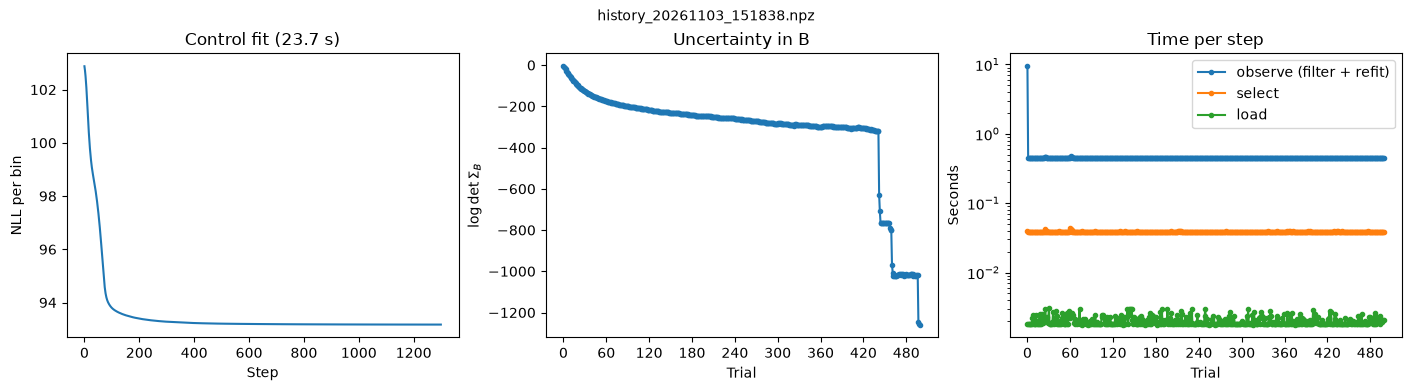

In [15]:
trials = np.arange(n)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), constrained_layout=True)

axes[0].plot(losses)
axes[0].set(xlabel="Step", ylabel="NLL per bin", title=f"Control fit ({float(h['control_fit_s']):.1f} s)")

axes[1].plot(trials, h["logdet"], marker="o", ms=3)
axes[1].set(xlabel="Trial", ylabel=r"$\log\det \Sigma_B$", title="Uncertainty in B")

for key, label in (("fitting_s", "fitting (filter + refit)"), ("acquisition_s", "acquisition"), ("load_s", "load")):
    values = h[key][1:] if key == "acquisition_s" else h[key]  # acquisition_s[0] is the first stim
    axes[2].plot(trials, values, marker="o", ms=3, label=label)
axes[2].set(xlabel="Trial", ylabel="Seconds", title="Time per step", yscale="log")
axes[2].legend()

for ax in axes[1:]:
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
fig.suptitle(path.name, fontsize=10)
plt.show()